# Issue #7: Interpreting the Charging-Behaviour Association Rules

**Inputs (repository root):** `arm_rules_filtered.csv`, `arm_rules_final.csv`, `arm_rules_headline.csv` (Issue #6); `association_onehot.csv`, `association_baskets.csv` (Issue #5); `feature_engineered_sessions.csv` (Issue #12, for hours and energy)  
**Outputs (repository root):** `association_selected_rules_i7.csv` (final selected rules with interpretation), `association_profiles_i7.csv`, `association_figures_i7/`, `association_findings_i7.md`

**How the three measures are read here**
- **Support** → *how common*: the share of all sessions, also given as sessions per week of data, so it can be compared with charger capacity.
- **Confidence** → *how reliable*: "when A happens, C follows in N of 10 sessions".
- **Lift** → *how surprising*: how many times more likely C is when A holds than in a random session. Lift is what makes a rule interesting; confidence alone can be high just because C is common.

Every number in the findings is computed below.

In [1]:
from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")
import sys
ROOT = find_root("acn_clean_sessions.csv")
sys.path.insert(0, str(ROOT))

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "association_figures_i7"; FIG.mkdir(exist_ok=True)
filt = pd.read_csv(ROOT / "arm_rules_filtered.csv")
final = pd.read_csv(ROOT / "arm_rules_final.csv")
headline = pd.read_csv(ROOT / "arm_rules_headline.csv")
onehot = pd.read_csv(ROOT / "association_onehot.csv").set_index("transaction_id")
bask = pd.read_csv(ROOT / "association_baskets.csv", usecols=["transaction_id", "arrival_date", "regime"]).set_index("transaction_id").reindex(onehot.index)
sess = (pd.read_csv(ROOT / "feature_engineered_sessions.csv", usecols=["sessionID", "connected_h", "charging_h", "kWhDelivered"])
        .set_index("sessionID").reindex(onehot.index))
N = len(onehot)
WEEKS = bask["arrival_date"].nunique() / 7
ITEMS = list(onehot.columns); ATTR = {c: c.split("=")[0] for c in ITEMS}
col = {c: onehot[c].values.astype(bool) for c in ITEMS}
REG = sorted(bask["regime"].unique())
kept = filt[filt.status == "kept"].merge(final[["rule", "theme", "description"]], on="rule", how="left")
print(f"{N:,} sessions over {WEEKS:.0f} weeks with data | final rules: {len(kept)} "
      f"({int((~kept.policy_driven).sum())} driver behaviour, {int(kept.policy_driven.sum())} policy-driven) | headline: {len(headline)}")

31,387 sessions over 155 weeks with data | final rules: 295 (165 driver behaviour, 130 policy-driven) | headline: 16


## 1. Review of the generated rules

In [2]:
overview = kept.groupby(["policy_driven", "theme"]).agg(rules=("rule", "size"), median_support=("support", "median"),
                                                       median_confidence=("confidence", "median"), median_lift=("lift", "median"),
                                                       max_lift=("lift", "max"))
display(overview.style.format({"median_support": "{:.1%}", "median_confidence": "{:.0%}", "median_lift": "{:.2f}", "max_lift": "{:.2f}"}))
status = filt["status"].value_counts().to_frame("rules"); status["share"] = status["rules"] / len(filt)
display(status.style.format({"share": "{:.1%}"}))

,rules,share
status,,
weak,20025,57.0%
negative association,11584,33.0%
redundant,1351,3.8%
near-arithmetic,595,1.7%
by construction,524,1.5%
"time, not behaviour",517,1.5%
kept,295,0.8%
weak among app users,258,0.7%


## 2. Selecting the strongest meaningful relationships

Many final rules are variations of the same pattern (the same consequent with one extra condition). To keep one rule per pattern, rules are ranked by **leverage**: the extra sessions a rule explains beyond chance, as a share of all sessions. Leverage combines support and lift, so it prefers patterns that are both common and surprising. For each consequent, the rule with the highest leverage is kept, and the twelve strongest of those with lift ≥ 1.3 form the selected set. Policy-driven rules are listed separately.

In [3]:
def pick(df, n):
    best = df.sort_values("leverage", ascending=False).drop_duplicates("consequent")
    return best[best.lift >= 1.3].head(n)
selected = pick(kept[~kept.policy_driven], 12).copy()
policy_sel = pick(kept[kept.policy_driven], 5).copy()

def measure(antecedent, consequent, mask):
    a = mask.copy()
    for x in antecedent.split(" + "):
        a &= col[x]
    c = col[consequent][mask]
    if a.sum() < 100 or c.mean() == 0:
        return np.nan
    return ((a & col[consequent]).sum() / a.sum()) / c.mean()
for g in REG:
    m = (bask["regime"] == g).values
    selected[f"lift in {g}"] = [measure(r.antecedent, r.consequent, m) for r in selected.itertuples()]
reg_cols = [f"lift in {g}" for g in REG]
selected["regimes_with_lift_over_1.1"] = (selected[reg_cols] > 1.1).sum(axis=1).astype(str) + "/" + selected[reg_cols].notna().sum(axis=1).astype(str)
selected["in_headline"] = selected["rule"].isin(headline["rule"])

def interpret(r):
    per_week = r.sessions / WEEKS
    extra = r.leverage * N / WEEKS
    return pd.Series({
        "support_reading": f"{r.support:.1%} of sessions, about {per_week:.0f} a week",
        "confidence_reading": f"{r.confidence * 10:.1f} in 10 matching sessions",
        "lift_reading": f"{r.lift:.1f}x as likely as in a random session ({r.consequent_support:.0%} -> {r.confidence:.0%})",
        "extra_sessions_per_week": extra})
selected = pd.concat([selected, selected.apply(interpret, axis=1)], axis=1)
show = ["rule", "support", "confidence", "lift", "support_reading", "confidence_reading", "lift_reading", "regimes_with_lift_over_1.1"]
display(selected[show].style.format({"support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.2f}"}))
display(Markdown("\n".join(f"{i + 1}. {d}" for i, d in enumerate(selected["description"]))))
if len(policy_sel):
    display(Markdown("**Policy-driven rules (operator rules, reported separately)**"))
    display(policy_sel[["rule", "support", "confidence", "lift"]].style.format({"support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.2f}"}))

,rule,support,confidence,lift,support_reading,confidence_reading,lift_reading,regimes_with_lift_over_1.1
1,{stay=6-10h} -> {arrival=morning},22.3%,70%,1.69,"22.3% of sessions, about 45 a week",7.0 in 10 matching sessions,1.7x as likely as in a random session (41% -> 70%),4/4
2,{stay=under_2h} -> {charging_share=mostly_charging},18.1%,67%,1.63,"18.1% of sessions, about 37 a week",6.7 in 10 matching sessions,1.6x as likely as in a random session (41% -> 67%),4/4
8,{energy=under_2kWh} -> {power=low},12.4%,79%,1.92,"12.4% of sessions, about 25 a week",7.9 in 10 matching sessions,1.9x as likely as in a random session (41% -> 79%),4/4
64,{arrival=morning + charging_share=mostly_idle} -> {stay=6-10h},11.1%,68%,2.12,"11.1% of sessions, about 23 a week",6.8 in 10 matching sessions,2.1x as likely as in a random session (32% -> 68%),4/4
104,{request=not_met + stay=6-10h} -> {charging_share=mostly_idle},10.2%,65%,2.15,"10.2% of sessions, about 21 a week",6.5 in 10 matching sessions,2.2x as likely as in a random session (30% -> 65%),3/3
16,{stay=under_2h} -> {station=busy},16.6%,62%,1.37,"16.6% of sessions, about 34 a week",6.2 in 10 matching sessions,1.4x as likely as in a random session (45% -> 62%),3/4
47,{arrival=midday + day_type=weekday} -> {station=other},15.0%,73%,1.33,"15.0% of sessions, about 30 a week",7.3 in 10 matching sessions,1.3x as likely as in a random session (55% -> 73%),4/4
34,{arrival=evening + charging_share=mostly_charging} -> {stay=under_2h},5.4%,64%,2.38,"5.4% of sessions, about 11 a week",6.4 in 10 matching sessions,2.4x as likely as in a random session (27% -> 64%),4/4
284,{power=medium + request=not_met + station=busy} -> {energy=2-7kWh},5.4%,64%,1.79,"5.4% of sessions, about 11 a week",6.4 in 10 matching sessions,1.8x as likely as in a random session (36% -> 64%),2/2
141,{energy=over_21kWh + regime=R3_paid} -> {power=high},2.7%,73%,2.91,"2.7% of sessions, about 5 a week",7.3 in 10 matching sessions,2.9x as likely as in a random session (25% -> 73%),1/1


1. Sessions that stay 6-10 h: 70% arrive in the morning (06-10) (1.69x the overall rate of 41%).
2. Sessions that stay under 2 h: 67% are charging most of the stay (>= 80%) (1.63x the overall rate of 41%).
3. Sessions that take under 2 kWh: 79% charge below 3 kW (1.92x the overall rate of 41%).
4. Sessions that arrive in the morning (06-10) and are mostly idle (charging < 40% of the stay): 68% stay 6-10 h (2.12x the overall rate of 32%).
5. Sessions that get < 90% of the energy requested and stay 6-10 h: 65% are mostly idle (charging < 40% of the stay) (2.15x the overall rate of 30%).
6. Sessions that stay under 2 h: 62% use one of the busiest chargers (1.37x the overall rate of 45%).
7. Sessions that arrive at midday (10-14), on a weekday: 73% use a less busy charger (1.33x the overall rate of 55%).
8. Sessions that arrive in the evening (18-24) and are charging most of the stay (>= 80%): 64% stay under 2 h (2.38x the overall rate of 27%).
9. Sessions that charge at 3-5 kW and get < 90% of the energy requested and use one of the busiest chargers: 64% take 2-7 kWh (1.79x the overall rate of 36%).
10. Sessions that take over 21 kWh, under paid charging (R3): 73% charge at 5 kW or more (2.91x the overall rate of 25%).

**Policy-driven rules (operator rules, reported separately)**

,rule,support,confidence,lift
13,{regime=R3_paid} -> {user=claimed},39.6%,84%,1.61
11,{regime=R1_free} -> {user=unclaimed},26.4%,99%,2.07
116,{day_type=weekday + user=unclaimed} -> {power=low},24.1%,62%,1.49
148,{regime=R3_paid + user=unclaimed} -> {energy=under_2kWh},7.2%,95%,6.09
99,{stay=under_2h + user=unclaimed} -> {charging_share=mostly_charging},10.8%,78%,1.89


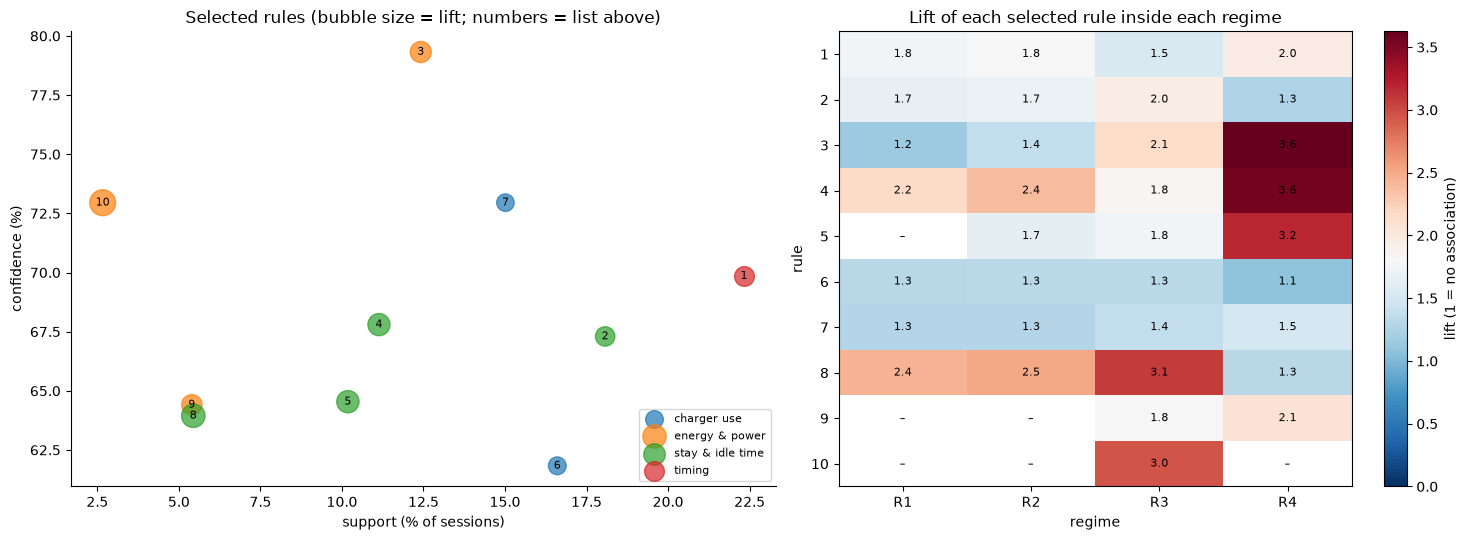

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for theme, g in selected.groupby("theme"):
    ax.scatter(g.support * 100, g.confidence * 100, s=g.lift * 120, alpha=0.7, label=theme)
for i, r in enumerate(selected.itertuples()):
    ax.annotate(str(i + 1), (r.support * 100, r.confidence * 100), ha="center", va="center", fontsize=8)
ax.set(xlabel="support (% of sessions)", ylabel="confidence (%)", title="Selected rules (bubble size = lift; numbers = list above)")
ax.legend(fontsize=8, loc="lower right"); ax.spines[["top", "right"]].set_visible(False)
ax = axes[1]
H = selected[reg_cols].values
im = ax.imshow(H, cmap="RdBu_r", vmin=0, vmax=2 * np.nanmax([1.0, np.nanmax(H) / 2]), aspect="auto")
ax.set_xticks(range(len(REG)), [g.split(" ")[0] for g in REG]); ax.set_yticks(range(len(selected)), [str(i + 1) for i in range(len(selected))])
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, "–" if np.isnan(H[i, j]) else f"{H[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set(title="Lift of each selected rule inside each regime", xlabel="regime", ylabel="rule"); ax.grid(False)
fig.colorbar(im, ax=ax, label="lift (1 = no association)")
plt.tight_layout(); plt.savefig(FIG / "R01_selected_rules.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Recurring behaviour combinations → charging profiles

The strongest rules describe a few recurring kinds of visit. They are turned into **mutually exclusive profiles**, defined only by arrival time and stay length (known when the car leaves), and every session is assigned to exactly one:

| Profile | Definition |
|---|---|
| Workday commuter | arrives 06–10 and stays 6 h or more |
| Quick top-up | stays under 2 h |
| Short visit | stays 2–6 h |
| Other long stay | stays 6 h or more, arriving outside 06–10 (afternoon, evening, night) |

For each profile: its share of sessions, of **charger-hours** (time plugged in), of **idle charger-hours** (plugged in but not charging) and of energy. A charger is occupied for the whole plug-in time, so charger-hours, not session counts, determine capacity.

,sessions,share_sessions,share_charger_hours,share_idle_hours,share_energy,idle_share_of_own_time,kWh_per_charger_hour,median_stay_h,weekend_share
profile,,,,,,,,,
Workday commuter,8702,28%,45%,50%,31%,54%,1.13,8.8,1%
Quick top-up,8428,27%,5%,1%,19%,13%,5.94,1.1,27%
Short visit,9609,31%,21%,14%,30%,33%,2.39,3.6,18%
Other long stay,4648,15%,29%,35%,21%,58%,1.21,8.7,15%


**Share of sessions by profile and regime**

,R1 free,"R2 free, 14 kWh default",R3 paid,R4 COVID period
profile,,,,
Workday commuter,27%,29%,32%,9%
Quick top-up,24%,27%,21%,56%
Short visit,32%,33%,30%,26%
Other long stay,16%,12%,17%,9%


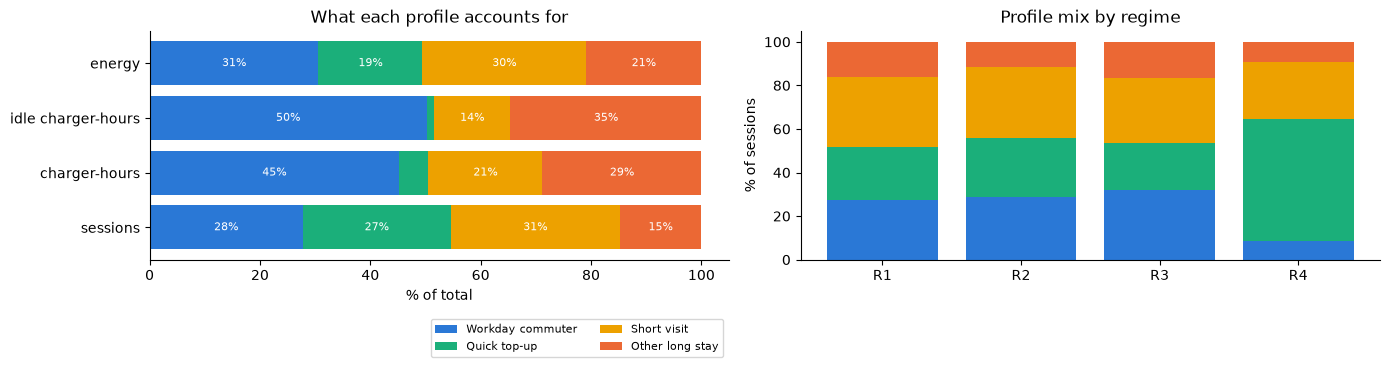

In [5]:
long_stay = col["stay=6-10h"] | col["stay=over_10h"]
profile = np.select([col["arrival=morning"] & long_stay, col["stay=under_2h"], col["stay=2-6h"], long_stay],
                    ["Workday commuter", "Quick top-up", "Short visit", "Other long stay"], default="unassigned")
assert (profile != "unassigned").all()
s = sess.assign(profile=profile, regime=bask["regime"].values, weekend=col["day_type=weekend"])
s["idle_h"] = (s["connected_h"] - s["charging_h"]).clip(lower=0)
known = s["charging_h"].notna()
def prof_table(d):
    k = d["charging_h"].notna()
    t = d.groupby("profile").agg(sessions=("connected_h", "size"), plugged_h=("connected_h", "sum"), energy=("kWhDelivered", "sum"),
                                 median_stay_h=("connected_h", "median"), weekend_share=("weekend", "mean"))
    idle = d[k].groupby("profile")["idle_h"].sum(); plug_k = d[k].groupby("profile")["connected_h"].sum()
    t["share_sessions"] = t["sessions"] / t["sessions"].sum()
    t["share_charger_hours"] = t["plugged_h"] / t["plugged_h"].sum()
    t["share_idle_hours"] = idle / idle.sum()
    t["share_energy"] = t["energy"] / t["energy"].sum()
    t["idle_share_of_own_time"] = idle / plug_k
    t["kWh_per_charger_hour"] = t["energy"] / t["plugged_h"]
    return t
profiles = prof_table(s)
order = ["Workday commuter", "Quick top-up", "Short visit", "Other long stay"]
profiles = profiles.reindex(order)
profiles[["sessions", "plugged_h", "energy", "share_sessions", "share_charger_hours", "share_idle_hours", "share_energy"]] = \
    profiles[["sessions", "plugged_h", "energy", "share_sessions", "share_charger_hours", "share_idle_hours", "share_energy"]].fillna(0)
evening = col["arrival=evening"]
profiles["evening_share"] = pd.Series(evening).groupby(profile).mean().reindex(order)
profiles.to_csv(ROOT / "association_profiles_i7.csv")
display(profiles[["sessions", "share_sessions", "share_charger_hours", "share_idle_hours", "share_energy", "idle_share_of_own_time",
                  "kWh_per_charger_hour", "median_stay_h", "weekend_share"]]
        .style.format({c: "{:.0%}" for c in ["share_sessions", "share_charger_hours", "share_idle_hours", "share_energy", "idle_share_of_own_time", "weekend_share"]}
                      | {"kWh_per_charger_hour": "{:.2f}", "median_stay_h": "{:.1f}"}))
by_reg = pd.concat({g: prof_table(s[s.regime == g])["share_sessions"] for g in REG}, axis=1).reindex(order).fillna(0)
display(Markdown("**Share of sessions by profile and regime**")); display(by_reg.style.format("{:.0%}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
metrics = ["share_sessions", "share_charger_hours", "share_idle_hours", "share_energy"]
labels = ["sessions", "charger-hours", "idle charger-hours", "energy"]
bottom = np.zeros(len(metrics)); colors = ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]
for p, c in zip(order, colors):
    v = profiles.loc[p, metrics].values.astype(float)
    axes[0].barh(labels, v * 100, left=bottom * 100, color=c, label=p)
    for i, (b, x) in enumerate(zip(bottom, v)):
        if x > 0.06: axes[0].text((b + x / 2) * 100, i, f"{x:.0%}", ha="center", va="center", fontsize=8, color="white")
    bottom += v
axes[0].set(xlabel="% of total", title="What each profile accounts for"); axes[0].legend(fontsize=8, ncol=2, loc="lower right", bbox_to_anchor=(1, -0.45))
bottom = np.zeros(len(REG))
for p, c in zip(order, colors):
    v = by_reg.loc[p].values.astype(float)
    axes[1].bar([g.split(" ")[0] for g in REG], v * 100, bottom=bottom * 100, color=c)
    bottom += v
axes[1].set(ylabel="% of sessions", title="Profile mix by regime")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "R02_profiles.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Rules about demand and charger utilisation

In [6]:
UTIL = {"stay", "charging_share", "station", "overnight"}
util_rules = kept[~kept.policy_driven & kept.consequent.map(ATTR).isin(UTIL)].sort_values("leverage", ascending=False)
util_sel = util_rules.drop_duplicates("consequent").head(6)
display(util_sel[["rule", "support", "confidence", "lift", "description"]].style.format({"support": "{:.1%}", "confidence": "{:.0%}", "lift": "{:.2f}"}))
busy_share = {g: onehot.loc[(bask.regime == g).values, "station=busy"].mean() for g in REG} if "station=busy" in onehot else {}
if busy_share:
    display(Markdown("**Share of sessions on the busiest 25% of chargers, by regime:** " + ", ".join(f"{g}: {v:.0%}" for g, v in busy_share.items())))

,rule,support,confidence,lift,description
2,{stay=under_2h} -> {charging_share=mostly_charging},18.1%,67%,1.63,Sessions that stay under 2 h: 67% are charging most of the stay (>= 80%) (1.63x the overall rate of 41%).
64,{arrival=morning + charging_share=mostly_idle} -> {stay=6-10h},11.1%,68%,2.12,Sessions that arrive in the morning (06-10) and are mostly idle (charging < 40% of the stay): 68% stay 6-10 h (2.12x the overall rate of 32%).
104,{request=not_met + stay=6-10h} -> {charging_share=mostly_idle},10.2%,65%,2.15,Sessions that get < 90% of the energy requested and stay 6-10 h: 65% are mostly idle (charging < 40% of the stay) (2.15x the overall rate of 30%).
16,{stay=under_2h} -> {station=busy},16.6%,62%,1.37,Sessions that stay under 2 h: 62% use one of the busiest chargers (1.37x the overall rate of 45%).
47,{arrival=midday + day_type=weekday} -> {station=other},15.0%,73%,1.33,"Sessions that arrive at midday (10-14), on a weekday: 73% use a less busy charger (1.33x the overall rate of 55%)."
34,{arrival=evening + charging_share=mostly_charging} -> {stay=under_2h},5.4%,64%,2.38,Sessions that arrive in the evening (18-24) and are charging most of the stay (>= 80%): 64% stay under 2 h (2.38x the overall rate of 27%).


**Share of sessions on the busiest 25% of chargers, by regime:** R1 free: 39%, R2 free, 14 kWh default: 38%, R3 paid: 41%, R4 COVID period: 85%

## 5. Limitations and possibly misleading associations

In [7]:
weak = filt[filt.status == "weak"]
trap = weak[(weak.confidence >= 0.8) & (weak.lift < 1.1)].sort_values("support", ascending=False).head(1)
simpson = selected[(selected[reg_cols] < 1.0).any(axis=1)]
pol_example = policy_sel.head(1)
lim = []
if len(trap):
    t = trap.iloc[0]
    lim.append(f"**High confidence is not enough.** {{{t.antecedent}}} -> {{{t.consequent}}} has confidence {t.confidence:.0%} but lift "
               f"{t.lift:.2f}: {t.consequent} is in {t.consequent_support:.0%} of all sessions anyway. Such rules were removed as weak.")
if len(simpson):
    r = simpson.iloc[0]; low = min((r[c], c.replace("lift in ", "")) for c in reg_cols if not np.isnan(r[c]))
    lim.append(f"**Pooling regimes can create or hide associations.** {r.rule} has lift {r.lift:.2f} over all sessions but {low[0]:.2f} in {low[1]}; "
               "part of the pooled pattern comes from regimes differing, not from behaviour within one regime.")
else:
    lim.append("**Pooling regimes:** every selected rule keeps lift >= 1.0 inside each regime with enough sessions, so none is an artefact of pooling regimes.")
if len(pol_example):
    p = pol_example.iloc[0]
    items_p = set(p.antecedent.split(" + ")) | {p.consequent}
    why = ("the 14 kWh default allowance for unclaimed sessions in R2" if "energy=13-14kWh_default" in items_p else
           "the 30-minute stop for unclaimed sessions under paid charging" if items_p & {"energy=under_2kWh", "power=low"} else
           "claim rates set by the pricing rules (1% of sessions claimed under free charging, most under paid charging, when unclaimed sessions are stopped after 30 minutes)")
    lim.append(f"**Operator rules look like behaviour.** {p.rule} (lift {p.lift:.2f}) reflects {why}, not driver choice; such rules are kept apart.")
miss = 1 - onehot[[c for c in ITEMS if ATTR[c] == "charging_share"]].sum(axis=1).clip(upper=1).mean()
lim += [
    "**Association is not causation.** A rule says two things occur together, e.g. morning arrival and a long stay; it does not say that one causes the other.",
    "**Categories depend on boundaries.** Stay, energy and power are binned (Issue #5); rules near a boundary (e.g. 6 h) can change with a different cut.",
    f"**Some items are missing.** Charging-share items are missing for {miss:.0%} of sessions (unreliable done-time), so idle-time rules describe the other {1 - miss:.0%}.",
    "**Some pairs are true by definition and were removed:** request outcome only exists for app users; overnight follows from arrival time + stay; energy, power, charging share and stay are linked arithmetically.",
    "**One site.** Caltech is a campus with some public use; the profile mix can differ at other workplaces.",
]
display(Markdown("\n".join(f"- {x}" for x in lim)))

- **High confidence is not enough.** {day_type=weekday} -> {overnight=no} has confidence 95% but lift 1.01: overnight=no is in 94% of all sessions anyway. Such rules were removed as weak.
- **Pooling regimes:** every selected rule keeps lift >= 1.0 inside each regime with enough sessions, so none is an artefact of pooling regimes.
- **Operator rules look like behaviour.** {regime=R3_paid} -> {user=claimed} (lift 1.61) reflects claim rates set by the pricing rules (1% of sessions claimed under free charging, most under paid charging, when unclaimed sessions are stopped after 30 minutes), not driver choice; such rules are kept apart.
- **Association is not causation.** A rule says two things occur together, e.g. morning arrival and a long stay; it does not say that one causes the other.
- **Categories depend on boundaries.** Stay, energy and power are binned (Issue #5); rules near a boundary (e.g. 6 h) can change with a different cut.
- **Some items are missing.** Charging-share items are missing for 7% of sessions (unreliable done-time), so idle-time rules describe the other 93%.
- **Some pairs are true by definition and were removed:** request outcome only exists for app users; overnight follows from arrival time + stay; energy, power, charging share and stay are linked arithmetically.
- **One site.** Caltech is a campus with some public use; the profile mix can differ at other workplaces.

## 6. Implications for workplace charging operations and the association-analysis findings (generated)

In [8]:
P = profiles
com, top = P.loc["Workday commuter"], P.loc["Quick top-up"]
idle_hog = P["share_idle_hours"].idxmax()
eff = P["kWh_per_charger_hour"].idxmax()
commuter_trend = by_reg.loc["Workday commuter"]
rule_lines = "\n".join(f"{i + 1}. {r['description']} Support: {r['support_reading']}; confidence: {r['confidence_reading']}; lift: {r['lift_reading']}. "
                       f"Holds (lift > 1.1) in {r['regimes_with_lift_over_1.1']} regimes."
                       for i, (_, r) in enumerate(selected.head(8).iterrows()))
all_we, all_ev = col["day_type=weekend"].mean(), evening.mean()
parts = []
if top.weekend_share > 1.2 * all_we: parts.append(f"at weekends ({top.weekend_share:.0%} of top-ups vs {all_we:.0%} of all sessions)")
if top.evening_share > 1.2 * all_ev: parts.append(f"in the evening ({top.evening_share:.0%} vs {all_ev:.0%})")
topup_txt = ("They are over-represented " + " and ".join(parts) + "; a few short-stay bays at those times serve many drivers." if parts else
             "They are spread across the week; a few short-stay bays with a time limit serve many drivers.")
if busy_share:
    hi_g, lo_g = max(busy_share, key=busy_share.get), min(busy_share, key=busy_share.get)
    conc_txt = (f"The busiest 25% of chargers take {busy_share[hi_g]:.0%} of sessions in {hi_g.split(' ')[0]} vs {busy_share[lo_g]:.0%} in {lo_g.split(' ')[0]}. "
                "Rotating assignments or signage spreads wear and keeps the other chargers in service."
                if busy_share[hi_g] - busy_share[lo_g] > 0.10 else
                f"The busiest 25% of chargers take {min(busy_share.values()):.0%}-{max(busy_share.values()):.0%} of sessions in every regime; rotating assignments spreads wear.")
else:
    conc_txt = "No charger-level item was available."
pmax = kept.loc[kept.policy_driven, "lift"].max() if kept.policy_driven.any() else np.nan
bmax = kept.loc[~kept.policy_driven, "lift"].max()
policy_txt = (f"{int(kept.policy_driven.sum())} of the {len(kept)} final rules are policy-driven (strongest lift {pmax:.2f} vs {bmax:.2f} for driver behaviour): "
              "the default allowance and the 30-minute stop for unclaimed sessions show up directly in energy, power and claim patterns."
              if kept.policy_driven.any() else "No policy-driven rules passed the thresholds.")
text = f"""# Issue #7: Charging-behaviour association findings (generated)

**Basis:** {len(kept)} final rules from Issue #6 ({int((~kept.policy_driven).sum())} driver behaviour, {int(kept.policy_driven.sum())} policy-driven), {N:,} sessions over {WEEKS:.0f} weeks with data. One rule per pattern, ranked by leverage (extra sessions explained). Full table: `association_selected_rules_i7.csv`.

## Strongest meaningful relationships
{rule_lines}

## Recurring behaviour profiles
- **Workday commuters** (arrive 06-10, stay >= 6 h): {com.share_sessions:.0%} of sessions but **{com.share_charger_hours:.0%} of charger-hours** and {com.share_idle_hours:.0%} of idle charger-hours; idle for {com.idle_share_of_own_time:.0%} of their own plug-in time.
- **Quick top-ups** (stay < 2 h): {top.share_sessions:.0%} of sessions, {top.share_charger_hours:.0%} of charger-hours, idle for {top.idle_share_of_own_time:.0%} of their time; {top.weekend_share:.0%} of them at weekends.
- **Short visits** (2-6 h): {P.loc['Short visit', 'share_sessions']:.0%} of sessions, {P.loc['Short visit', 'share_charger_hours']:.0%} of charger-hours. **Other long stays** (>= 6 h, not a morning arrival): {P.loc['Other long stay', 'share_sessions']:.0%} of sessions, {P.loc['Other long stay', 'share_charger_hours']:.0%} of charger-hours.
- The largest share of idle charger-hours comes from **{idle_hog.lower()}s**; the most energy per charger-hour from **{eff.lower()}s** ({P.loc[eff, 'kWh_per_charger_hour']:.2f} kWh per hour plugged in vs {P.loc[idle_hog, 'kWh_per_charger_hour']:.2f} for {idle_hog.lower()}s).
- Commuter share of sessions by regime: {', '.join(f"{g.split(' ')[0]} {v:.0%}" for g, v in commuter_trend.items())}.

## Implications for workplace charging
1. **Capacity is set by long stays, not by session counts.** {idle_hog}s hold {P.loc[idle_hog, 'share_charger_hours']:.0%} of charger-hours and {P.loc[idle_hog, 'share_idle_hours']:.0%} of idle hours. Freeing chargers once charging is done (idle fees after a grace period, move-your-car notifications, or valet swapping at midday) adds capacity without new hardware.
2. **Protect quick top-ups.** Short sessions deliver {top.kWh_per_charger_hour:.2f} kWh per charger-hour vs {com.kWh_per_charger_hour:.2f} for commuters. {topup_txt}
3. **Plan the morning peak.** Commuters arrive together in 06-10 and stay all day, so the chargers they occupy are blocked until afternoon; peak occupancy (Issue #16/#17) follows from this pattern.
4. **Watch charger concentration.** {conc_txt}
5. **Pricing and access rules shape behaviour.** {policy_txt} Any change in pricing or access rules should be expected to change these patterns, and the rules should be re-mined after it.

## Limitations
{chr(10).join('- ' + x for x in lim)}
"""
out_cols = ["rule", "theme", "support", "confidence", "lift", "leverage", "sessions", "support_reading", "confidence_reading", "lift_reading",
            "extra_sessions_per_week", "regimes_with_lift_over_1.1", "in_headline", "description"] + reg_cols
pd.concat([selected.assign(policy_driven=False), policy_sel.assign(policy_driven=True)], ignore_index=True)[
    [c for c in out_cols + ["policy_driven"] if c in selected.columns or c == "policy_driven"]].to_csv(ROOT / "association_selected_rules_i7.csv", index=False)
(ROOT / "association_findings_i7.md").write_text(text, encoding="utf-8")
display(Markdown(text))

# Issue #7: Charging-behaviour association findings (generated)

**Basis:** 295 final rules from Issue #6 (165 driver behaviour, 130 policy-driven), 31,387 sessions over 155 weeks with data. One rule per pattern, ranked by leverage (extra sessions explained). Full table: `association_selected_rules_i7.csv`.

## Strongest meaningful relationships
1. Sessions that stay 6-10 h: 70% arrive in the morning (06-10) (1.69x the overall rate of 41%). Support: 22.3% of sessions, about 45 a week; confidence: 7.0 in 10 matching sessions; lift: 1.7x as likely as in a random session (41% -> 70%). Holds (lift > 1.1) in 4/4 regimes.
2. Sessions that stay under 2 h: 67% are charging most of the stay (>= 80%) (1.63x the overall rate of 41%). Support: 18.1% of sessions, about 37 a week; confidence: 6.7 in 10 matching sessions; lift: 1.6x as likely as in a random session (41% -> 67%). Holds (lift > 1.1) in 4/4 regimes.
3. Sessions that take under 2 kWh: 79% charge below 3 kW (1.92x the overall rate of 41%). Support: 12.4% of sessions, about 25 a week; confidence: 7.9 in 10 matching sessions; lift: 1.9x as likely as in a random session (41% -> 79%). Holds (lift > 1.1) in 4/4 regimes.
4. Sessions that arrive in the morning (06-10) and are mostly idle (charging < 40% of the stay): 68% stay 6-10 h (2.12x the overall rate of 32%). Support: 11.1% of sessions, about 23 a week; confidence: 6.8 in 10 matching sessions; lift: 2.1x as likely as in a random session (32% -> 68%). Holds (lift > 1.1) in 4/4 regimes.
5. Sessions that get < 90% of the energy requested and stay 6-10 h: 65% are mostly idle (charging < 40% of the stay) (2.15x the overall rate of 30%). Support: 10.2% of sessions, about 21 a week; confidence: 6.5 in 10 matching sessions; lift: 2.2x as likely as in a random session (30% -> 65%). Holds (lift > 1.1) in 3/3 regimes.
6. Sessions that stay under 2 h: 62% use one of the busiest chargers (1.37x the overall rate of 45%). Support: 16.6% of sessions, about 34 a week; confidence: 6.2 in 10 matching sessions; lift: 1.4x as likely as in a random session (45% -> 62%). Holds (lift > 1.1) in 3/4 regimes.
7. Sessions that arrive at midday (10-14), on a weekday: 73% use a less busy charger (1.33x the overall rate of 55%). Support: 15.0% of sessions, about 30 a week; confidence: 7.3 in 10 matching sessions; lift: 1.3x as likely as in a random session (55% -> 73%). Holds (lift > 1.1) in 4/4 regimes.
8. Sessions that arrive in the evening (18-24) and are charging most of the stay (>= 80%): 64% stay under 2 h (2.38x the overall rate of 27%). Support: 5.4% of sessions, about 11 a week; confidence: 6.4 in 10 matching sessions; lift: 2.4x as likely as in a random session (27% -> 64%). Holds (lift > 1.1) in 4/4 regimes.

## Recurring behaviour profiles
- **Workday commuters** (arrive 06-10, stay >= 6 h): 28% of sessions but **45% of charger-hours** and 50% of idle charger-hours; idle for 54% of their own plug-in time.
- **Quick top-ups** (stay < 2 h): 27% of sessions, 5% of charger-hours, idle for 13% of their time; 27% of them at weekends.
- **Short visits** (2-6 h): 31% of sessions, 21% of charger-hours. **Other long stays** (>= 6 h, not a morning arrival): 15% of sessions, 29% of charger-hours.
- The largest share of idle charger-hours comes from **workday commuters**; the most energy per charger-hour from **quick top-ups** (5.94 kWh per hour plugged in vs 1.13 for workday commuters).
- Commuter share of sessions by regime: R1 27%, R2 29%, R3 32%, R4 9%.

## Implications for workplace charging
1. **Capacity is set by long stays, not by session counts.** Workday commuters hold 45% of charger-hours and 50% of idle hours. Freeing chargers once charging is done (idle fees after a grace period, move-your-car notifications, or valet swapping at midday) adds capacity without new hardware.
2. **Protect quick top-ups.** Short sessions deliver 5.94 kWh per charger-hour vs 1.13 for commuters. They are over-represented at weekends (27% of top-ups vs 15% of all sessions) and in the evening (28% vs 15%); a few short-stay bays at those times serve many drivers.
3. **Plan the morning peak.** Commuters arrive together in 06-10 and stay all day, so the chargers they occupy are blocked until afternoon; peak occupancy (Issue #16/#17) follows from this pattern.
4. **Watch charger concentration.** The busiest 25% of chargers take 85% of sessions in R4 vs 38% in R2. Rotating assignments or signage spreads wear and keeps the other chargers in service.
5. **Pricing and access rules shape behaviour.** 130 of the 295 final rules are policy-driven (strongest lift 6.09 vs 2.91 for driver behaviour): the default allowance and the 30-minute stop for unclaimed sessions show up directly in energy, power and claim patterns. Any change in pricing or access rules should be expected to change these patterns, and the rules should be re-mined after it.

## Limitations
- **High confidence is not enough.** {day_type=weekday} -> {overnight=no} has confidence 95% but lift 1.01: overnight=no is in 94% of all sessions anyway. Such rules were removed as weak.
- **Pooling regimes:** every selected rule keeps lift >= 1.0 inside each regime with enough sessions, so none is an artefact of pooling regimes.
- **Operator rules look like behaviour.** {regime=R3_paid} -> {user=claimed} (lift 1.61) reflects claim rates set by the pricing rules (1% of sessions claimed under free charging, most under paid charging, when unclaimed sessions are stopped after 30 minutes), not driver choice; such rules are kept apart.
- **Association is not causation.** A rule says two things occur together, e.g. morning arrival and a long stay; it does not say that one causes the other.
- **Categories depend on boundaries.** Stay, energy and power are binned (Issue #5); rules near a boundary (e.g. 6 h) can change with a different cut.
- **Some items are missing.** Charging-share items are missing for 7% of sessions (unreliable done-time), so idle-time rules describe the other 93%.
- **Some pairs are true by definition and were removed:** request outcome only exists for app users; overnight follows from arrival time + stay; energy, power, charging share and stay are linked arithmetically.
- **One site.** Caltech is a campus with some public use; the profile mix can differ at other workplaces.


## Issue #7 checklist → where it is done

| Task | Section |
|---|---|
| Review the generated association rules | 1 |
| Identify the strongest meaningful relationships | 2 |
| Interpret support / confidence / lift for the selected rules | 2 (`support_reading`, `confidence_reading`, `lift_reading` columns) |
| Identify recurring charging-behaviour combinations | 3 (profiles) |
| Identify patterns related to charging demand or utilisation | 3, 4 |
| Connect meaningful rules to workplace charging operations | 6 |
| Identify implications for charging management and capacity planning | 6 |
| Document limitations and possibly misleading associations | 5 |
| Prepare a concise set of association-analysis findings | 6 (`association_findings_i7.md`) |